<a href="https://colab.research.google.com/github/Parth-22k/ML-Lab/blob/main/Exp9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


Accuracy: 58.78 %

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.43      0.49       112
           1       0.60      0.72      0.66       133

    accuracy                           0.59       245
   macro avg       0.58      0.58      0.57       245
weighted avg       0.58      0.59      0.58       245



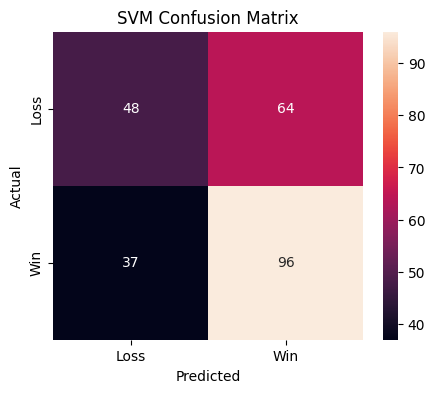

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Load dataset
df = pd.read_csv('/content/drive/MyDrive/ML/cricket_svm_cleaned.csv')

# 2. Separate features and target
X = df.drop('Result', axis=1)
y = df['Result']

# 3. Categorical columns
cat_cols = ['Toss', 'Bat', 'Opposition', 'Ground', 'Country']

# 4. Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

# 5. Create SVM model
model = Pipeline([
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler(with_mean=False)),
    ('svm', SVC(kernel='linear'))
])

# 6. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 7. Train model
model.fit(X_train, y_train)

# 8. Prediction
y_pred = model.predict(X_test)

# 9. Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")

# 10. Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 11. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Loss', 'Win'],
    yticklabels=['Loss', 'Win']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")
plt.show()